# HMLA-Net — regenerating the paper's numbers, tables and figures from the archived run outputs

**Paper:** Songul Karakus, Mehmet Burukanli. *Saturated In-Domain, Separable Out-of-Domain: A Hierarchical Multi-Scale Lesion-Attention Network and a Zero-Shot Cross-Corpus Protocol for Multi-Crop Leaf Disease Classification.* Symmetry 2026, **18**(9), 1557. [DOI 10.3390/sym18091557](https://doi.org/10.3390/sym18091557) (open access, CC BY 4.0).

**Code:** [github.com/songulkarakus/HMLA-Net](https://github.com/songulkarakus/HMLA-Net) (MIT), pinned commit `101f31a461a1a5782d25e616b235f71ced90b21c` (release v1.1.2, the version cited in the article).

## What this notebook does — exact scope

The authors ship a paper archive (`paper/`) with all run outputs of their two benchmark executions plus the scripts that derive every quoted number. This notebook executes the **authors' own reproduction chain, unmodified**:

1. a pinned, blobless Git clone of the repository (code + archived run outputs, ~47 MB),
2. the release asset `predictions.zip` (243,325,854 bytes; per-image predictions of 278 runs),
3. `bash paper/scripts/reproduce.sh` → `derive_A.py`, `derive_numbers_rev.py`, `make_figures_rev.py`, `make_tables_rev.py`, `make_tables_submitted.py`, `compare_numbers.py`,
4. the pass/fail gate: `compare_numbers.py` must report the regenerated `output/numbers.json` **identical** to the frozen `reference/numbers.json`,
5. re-computation of the replication-A statistics with `analyze.py` and comparison against the archived copies in the Git tree.

**Not in scope:** training any of the 26 architectures, zero-shot inference on the Mendeley corpora (the authors release no trained checkpoints — `best.pth` files are absent from the repository and releases), and the optional within-corpus near-duplicate scan whose outputs are committed. This notebook validates the paper's *reporting chain* on a CPU runtime; it does not re-run the experiments.

**Provenance note (EN):** All scientific steps are the authors' own pinned scripts. The glue cells (clone, download, size verification, figure display) are AI-authored and explicitly labeled; no author script was modified. *(JA)* 本ノートブックは著者自身の再現スクリプトを未修正のまま実行します。クローン・ダウンロード・検証などの補助セルのみ AI が作成しました。学習・推論は対象外です。

## Runtime selection — CPU only / ランタイム選択

The reproduction chain is pandas/scipy/numpy over archived outputs; the authors state it "takes a few minutes on a laptop and needs no GPU" (`paper/README.md`). **Select Runtime → Change runtime type → CPU.** No torch is installed and no GPU branch exists; on a GPU runtime everything still works identically (nothing in the chain uses it).

Expected cost (estimates, measured values printed in the run cells): ~290 MB downloads (repository ~47 MB + `predictions.zip` ~240 MB) and roughly 10–20 minutes end-to-end including the chain run.

*(JA)* この再現は CPU のみで実行できます（著者報告「ラップトップで数分、GPU 不要」）。ランタイム type は **CPU** を選択してください。ダウンロード約 290 MB、全体で 10〜20 分程度の見込みです。すべてのセルを上から **Run all** で実行します。

### Environment check
Verifies Python ≥ 3.10 and the exact dependency set that `paper/README.md` requires (numpy, pandas, scipy, scikit-learn, matplotlib, Pillow). These are preinstalled on standard Colab CPU runtimes; if anything is missing the cell fails loudly with the install line instead of proceeding silently. *(JA)* 必要パッケージの有無を確認します。欠けていればインストール指示とともに明示的に停止します。

In [ ]:
import sys, importlib
from pathlib import Path

if sys.version_info < (3, 10):
    raise RuntimeError(f"Python >= 3.10 required, found {sys.version}")

REQUIRED = ["numpy", "pandas", "scipy", "sklearn", "matplotlib", "PIL"]
versions = {}
for mod in REQUIRED:
    try:
        m = importlib.import_module(mod)
    except ImportError as e:
        raise RuntimeError(
            f"Missing dependency '{mod}'. Install with: "
            "pip install numpy pandas scipy scikit-learn matplotlib Pillow"
        ) from e
    versions[mod] = getattr(m, "__version__", "?")

print("Python:", sys.version.split()[0])
for k, v in versions.items():
    print(f"  {k:12s} {v}")

Python: 3.13.16
  numpy        2.1.3
  pandas       2.2.3
  scipy        1.16.3
  sklearn      1.6.1
  matplotlib   3.10.0
  PIL          11.3.0


### Pinned repository acquisition (AI-authored glue cell)
Blobless clone (`--filter=blob:none --no-checkout`) of the author repository, then an explicit detached checkout of the pinned commit `101f31a4…` — the exact version cited in the paper (release v1.1.2). The checkout is verified by comparing `git rev-parse HEAD` with the pinned SHA; a mismatch or a moved commit aborts. All repository bytes stay under `/content` on the Colab VM. *(JA)* 論文が引用するバージョン（v1.1.2）に固定したコミットを blob なしクローンで取得し、 detached HEAD でチェックアウトして SHA を検証します。

In [ ]:
import subprocess
from pathlib import Path

REPO = Path("/content/HMLA-Net")
REPO_URL = "https://github.com/songulkarakus/HMLA-Net"
PINNED = "101f31a461a1a5782d25e616b235f71ced90b21c"

if not (REPO / ".git").exists():
    subprocess.run(["git", "clone", "--filter=blob:none", "--no-checkout",
                    REPO_URL, str(REPO)], check=True)
subprocess.run(["git", "-C", str(REPO), "checkout", "--detach", PINNED], check=True,
               capture_output=True, text=True)
head = subprocess.run(["git", "-C", str(REPO), "rev-parse", "HEAD"],
                      capture_output=True, text=True, check=True).stdout.strip()
assert head == PINNED, f"checkout mismatch: {head}"
n_files = len(subprocess.run(["git", "-C", str(REPO), "ls-files"],
                             capture_output=True, text=True, check=True).stdout.splitlines())
print("checked out pinned commit:", head[:12], "(verified)")
print("worktree files:", n_files)

checked out pinned commit: 101f31a461a1 (verified)
worktree files: 2451


### Release asset `predictions.zip` — provenance and verified download (AI-authored glue cell)
The per-image predictions of the 278 runs (712 `.npz` files) are attached to release **v1.1.2**; the GitHub API lists the asset as `predictions.zip`, **243,325,854 bytes** (metadata checked on 2026-10-23). The cell downloads it into `paper/`, verifies the exact byte size (no author-recorded SHA-256 exists; the size check plus the chain's full parsing of every `.npz` and the `compare_numbers.py` equality gate serve as integrity evidence), unpacks it next to `replication_A/` and `replication_B/` — exactly the layout `reproduce.sh` expects — and removes the archive. When the sentinel file is already present, the download is skipped (idempotent). *(JA)* リリース v1.1.2 添付の `predictions.zip`（243,325,854 バイト）をサイズ検証付きでダウンロードし、`reproduce.sh` が期待する位置に展開します。検証済みなら再ダウンロードしません。

In [ ]:
import shutil
import urllib.request

PAPER_DIR = REPO / "paper"
ZIP_PATH = PAPER_DIR / "predictions.zip"
SENTINEL = PAPER_DIR / "replication_A/runs/proposed/Proposed_HMLA_CAFormerS18/seed42/predictions_test.npz"
ZIP_URL = "https://github.com/songulkarakus/HMLA-Net/releases/download/v1.1.2/predictions.zip"
EXPECTED_SIZE = 243_325_854

if not SENTINEL.exists():
    if not (ZIP_PATH.exists() and ZIP_PATH.stat().st_size == EXPECTED_SIZE):
        print("downloading", ZIP_URL)
        with urllib.request.urlopen(ZIP_URL) as resp, open(ZIP_PATH, "wb") as fh:
            shutil.copyfileobj(resp, fh)
    got = ZIP_PATH.stat().st_size
    assert got == EXPECTED_SIZE, f"size mismatch: {got} != {EXPECTED_SIZE}"
    print(f"size verified: {got:,} bytes; unpacking ...")
    subprocess.run(["unzip", "-q", "-o", ZIP_PATH.name], cwd=PAPER_DIR, check=True)
    ZIP_PATH.unlink()
assert SENTINEL.exists(), "sentinel predictions_test.npz missing after unpack"
print("sentinel present:", SENTINEL.relative_to(REPO))

downloading https://github.com/songulkarakus/HMLA-Net/releases/download/v1.1.2/predictions.zip


size verified: 243,325,854 bytes; unpacking ...


sentinel present: paper/replication_A/runs/proposed/Proposed_HMLA_CAFormerS18/seed42/predictions_test.npz


## Input preview — the archived run outputs / 入力データの確認

This reproduction has **no raw leaf images as input**: its inputs are the archived run artifacts committed in the Git tree — `master_results.csv` (one row per run/split with the full metric set), per-run `metrics_test.json` / `metrics_external_mld24.json` / per-class CSVs, `selection.json`, and the per-image `predictions_*.npz` unpacked above. The cell below shows shape, columns and a few rows of `master_results.csv` plus the top of the curated replication-A internal-test summary, so the data the chain will consume is visible before anything is derived. *(JA)* この再現の入力は生の葉画像ではなく、リポジトリに収録済みの実行結果（指標 CSV/JSON と予測 npz）です。まずその構成を確認します。

In [ ]:
import pandas as pd

pd.set_option("display.width", 160)
master = pd.read_csv(REPO / "paper/replication_A/runs/master_results.csv")
print("replication_A/runs/master_results.csv:", master.shape[0], "rows x", master.shape[1], "columns")
print("columns:", list(master.columns))
display(master.head(3))

summary = pd.read_csv(REPO / "paper/replication_A/summary/summary_internal_test.csv")
print("\nreplication_A/summary/summary_internal_test.csv:", summary.shape[0], "models")
display(summary.head(5))

replication_A/runs/master_results.csv: 356 rows x 38 columns
columns: ['tag', 'experiment', 'model', 'seed', 'split', 'n_test', 'accuracy', 'balanced_accuracy', 'top5_accuracy', 'precision_macro', 'recall_macro', 'f1_macro', 'precision_weighted', 'recall_weighted', 'f1_weighted', 'sensitivity_macro', 'specificity_macro', 'g_mean_macro', 'cohen_kappa', 'mcc', 'auc_macro_ovr', 'auc_weighted_ovr', 'average_precision_macro', 'log_loss', 'ece', 'n_zero_recall_classes', 'params_M', 'size_MB', 'gflops', 'latency_ms', 'latency_ms_single_pass', 'tta_views', 'fps', 'train_sec', 'n_epochs', 'best_epoch', 'select_src', 'hier_beta']


,tag,experiment,model,seed,split,n_test,accuracy,balanced_accuracy,top5_accuracy,precision_macro,...,gflops,latency_ms,latency_ms_single_pass,tta_views,fps,train_sec,n_epochs,best_epoch,select_src,hier_beta
0,proposed/Proposed_HMLA_CAFormerS18/seed42,proposed,caformer_s18.sail_in22k_ft_in1k,42,internal_test,1077,0.987929,0.984116,1.000000,0.986303,...,3.970554,44.383,11.096,4.0,22.5,961.1,28.0,19.0,ema,0.0
1,proposed/Proposed_HMLA_CAFormerS18/seed42,proposed,caformer_s18.sail_in22k_ft_in1k,42,external,3000,0.903000,0.903000,0.941333,0.938685,...,3.970554,44.383,11.096,4.0,22.5,961.1,28.0,19.0,ema,0.0
2,benchmark/resnet50/seed42,benchmark,resnet50,42,internal_test,1077,0.974002,0.968176,0.998143,0.971274,...,4.109508,6.052,6.052,1.0,165.2,436.4,31.0,22.0,raw,NaN



replication_A/summary/summary_internal_test.csv: 26 models


,model,n_seeds,accuracy_mean,accuracy_std,accuracy_n,balanced_accuracy_mean,balanced_accuracy_std,balanced_accuracy_n,top5_accuracy_mean,top5_accuracy_std,...,gflops,latency_ms,latency_ms_single_pass,tta_views,fps,select_src,hier_beta,best_epoch,train_sec_mean,complete
0,Proposed_HMLA_CAFormerS18,3,0.988239,0.001418,3,0.984713,0.000746,3,1.000000,0.000000,...,3.970554,44.383,11.096,4,22.5,ema,0.0,19,864.366667,True
1,swin_small_patch4_window7_224,3,0.988239,0.002985,3,0.984376,0.004360,3,0.999381,0.000536,...,8.767783,11.512,11.512,1,86.9,raw,NaN,17,768.833333,True
2,vgg16,3,0.987310,0.002985,3,0.984126,0.004143,3,0.999690,0.000536,...,15.466258,6.685,6.685,1,149.6,raw,NaN,29,899.433333,True
3,legacy_seresnext50_32x4d,3,0.987929,0.000929,3,0.984140,0.000835,3,0.999381,0.001072,...,4.259891,6.040,6.040,1,165.6,raw,NaN,25,480.066667,True
4,regnety_016,3,0.987310,0.003515,3,0.983611,0.004283,3,0.999690,0.000536,...,1.627318,11.113,11.113,1,90.0,raw,NaN,30,353.600000,True


## Reproduction chain — the authors' own script / 著者スクリプトの実行

Runs `bash paper/scripts/reproduce.sh` **unmodified** from the pinned checkout. The script: (1) skips its own download because the sentinel `.npz` exists, (2) `derive_A.py` — zero-shot protocols P1–P3 and label leakage from the replication-A predictions, clean-test re-scoring, parameter fits, six-class internal accuracy, (3) `derive_numbers_rev.py` — every quoted number → `output/numbers.json` + `output/derived/*.csv`, (4) `make_figures_rev.py` — 600 dpi figures → `output/figures/`, (5) `make_tables_rev.py` — table LaTeX bodies → `output/tables/`, (6) `make_tables_submitted.py` — Tables 3/7/8 regenerated and checked against `scripts/tables_submitted/`, (7) `compare_numbers.py` — equality against `reference/numbers.json`. The script exits non-zero on any failure; the cell raises and preserves the full output. Wall time is measured. *(JA)* 著者の `reproduce.sh` を未修正のまま実行します（ゼロショット解析 → 数値導出 → 図 → 表 → 提出版表の一致確認 → 参照値との一致ゲート）。失敗時は非ゼロ終了で例外を投げます。

In [ ]:
import time

t0 = time.time()
proc = subprocess.run(["bash", "paper/scripts/reproduce.sh"], cwd=REPO,
                      text=True)  # output streams live; return code is authoritative
elapsed = time.time() - t0
print(f"\n[glue] reproduce.sh exit code: {proc.returncode}, wall time: {elapsed:.1f} s")
if proc.returncode != 0:
    raise RuntimeError(f"reproduce.sh failed with exit code {proc.returncode}")


[glue] reproduce.sh exit code: 0, wall time: 38.1 s


### Verification gate and headline numbers
Re-runs `compare_numbers.py` explicitly so its verdict is visible: it exits non-zero and lists differing paths if the regenerated `output/numbers.json` deviates from the frozen `reference/numbers.json` (float tolerance 1e-9). Then the curated headline quantities are read from the regenerated `numbers.json` — the internal saturation, the zero-shot spread and the replication statistics — and displayed as a small table. Missing keys would print as absent rather than being invented. *(JA)* `compare_numbers.py` を明示的に再実行して参照値との一致を可視化し、`numbers.json` から主要な数値（内部性能の飽和、ゼロショットのばらつき、再現統計）を抽出して表示します。

In [ ]:
import json

r = subprocess.run([sys.executable, "scripts/compare_numbers.py"], cwd=PAPER_DIR,
                   capture_output=True, text=True)
print(r.stdout.strip())
print("[glue] compare_numbers.py exit code:", r.returncode)
if r.returncode != 0:
    raise RuntimeError("regenerated numbers.json differs from reference/numbers.json")

N = json.loads((PAPER_DIR / "output/numbers.json").read_text())

def dig(obj, path):
    cur = obj
    for k in path.split("."):
        if not isinstance(cur, dict) or k not in cur:
            return None
        cur = cur[k]
    return cur

HEADLINES = [
    ("internal.proposed_f1", "HMLA-Net internal macro-F1"),
    ("internal.f1_spread26_pp", "internal macro-F1 spread across 26 models (pp)"),
    ("internal.proposed_rank31", "HMLA-Net internal rank"),
    ("external.proposed_acc", "HMLA-Net zero-shot accuracy"),
    ("external.acc_spread26_pp", "zero-shot accuracy spread (pp)"),
    ("external.best_f1_model", "best zero-shot model"),
    ("external.best_f1", "best zero-shot macro-F1"),
    ("stats.friedman_all.p", "Friedman test p (all models)"),
    ("stats.friedman_all.cd", "critical difference"),
    ("replication.external_f1.mean_abs_pp", "zero-shot run-to-run mean abs gap (pp)"),
    ("replication.spread_to_noise_external", "external spread-to-noise ratio"),
    ("A.zero_recall", "zero-recall class evidence"),
]
rows = []
for path, label in HEADLINES:
    v = dig(N, path)
    if isinstance(v, dict):
        v = json.dumps(v)[:80]
    rows.append({"key": path, "quantity": label, "value": v})
display(pd.DataFrame(rows))

output/numbers.json is identical to reference/numbers.json (67806 characters).
[glue] compare_numbers.py exit code: 0


,key,quantity,value
0,internal.proposed_f1,HMLA-Net internal macro-F1,0.9828
1,internal.f1_spread26_pp,internal macro-F1 spread across 26 models (pp),1.72
2,internal.proposed_rank31,HMLA-Net internal rank,11
3,external.proposed_acc,HMLA-Net zero-shot accuracy,0.704
4,external.acc_spread26_pp,zero-shot accuracy spread (pp),44.0
5,external.best_f1_model,best zero-shot model,swin_small_patch4_window7_224
6,external.best_f1,best zero-shot macro-F1,0.6974
7,stats.friedman_all.p,Friedman test p (all models),0.0011
8,stats.friedman_all.cd,critical difference,27.83
9,replication.external_f1.mean_abs_pp,zero-shot run-to-run mean abs gap (pp),3.285


## Regenerated figures / 再生された図
`make_figures_rev.py` writes 600 dpi figures into `paper/output/figures/`. Four representative ones are displayed inline (downscaled for the notebook; the originals keep full resolution on the VM): the internal-test ranking of the 26 architectures, the Friedman/Nemenyi critical-difference diagram, the zero-shot transfer figure and the replication-A-vs-B comparison. These are regenerated from the archived outputs in this run — not screenshots. *(JA)* `output/figures/` に生成された図のうち代表 4 枚（内部ランキング、臨界差図、ゼロショット転移、再現比較）を縮小表示します。

figures generated: ['fig10_tsne.png', 'fig11_efficiency.png', 'fig12_forensics.png', 'fig13_lap.png', 'fig1_dataset.png', 'fig3_internal_ranking.png', 'fig4_cd_diagram.png', 'fig5_transfer.png', 'fig6_replication.png', 'fig7_ablation.png', 'fig8_perclass.png', 'fig9_gradcam.png']


fig3_internal_ranking.png -> (1200, 1407)


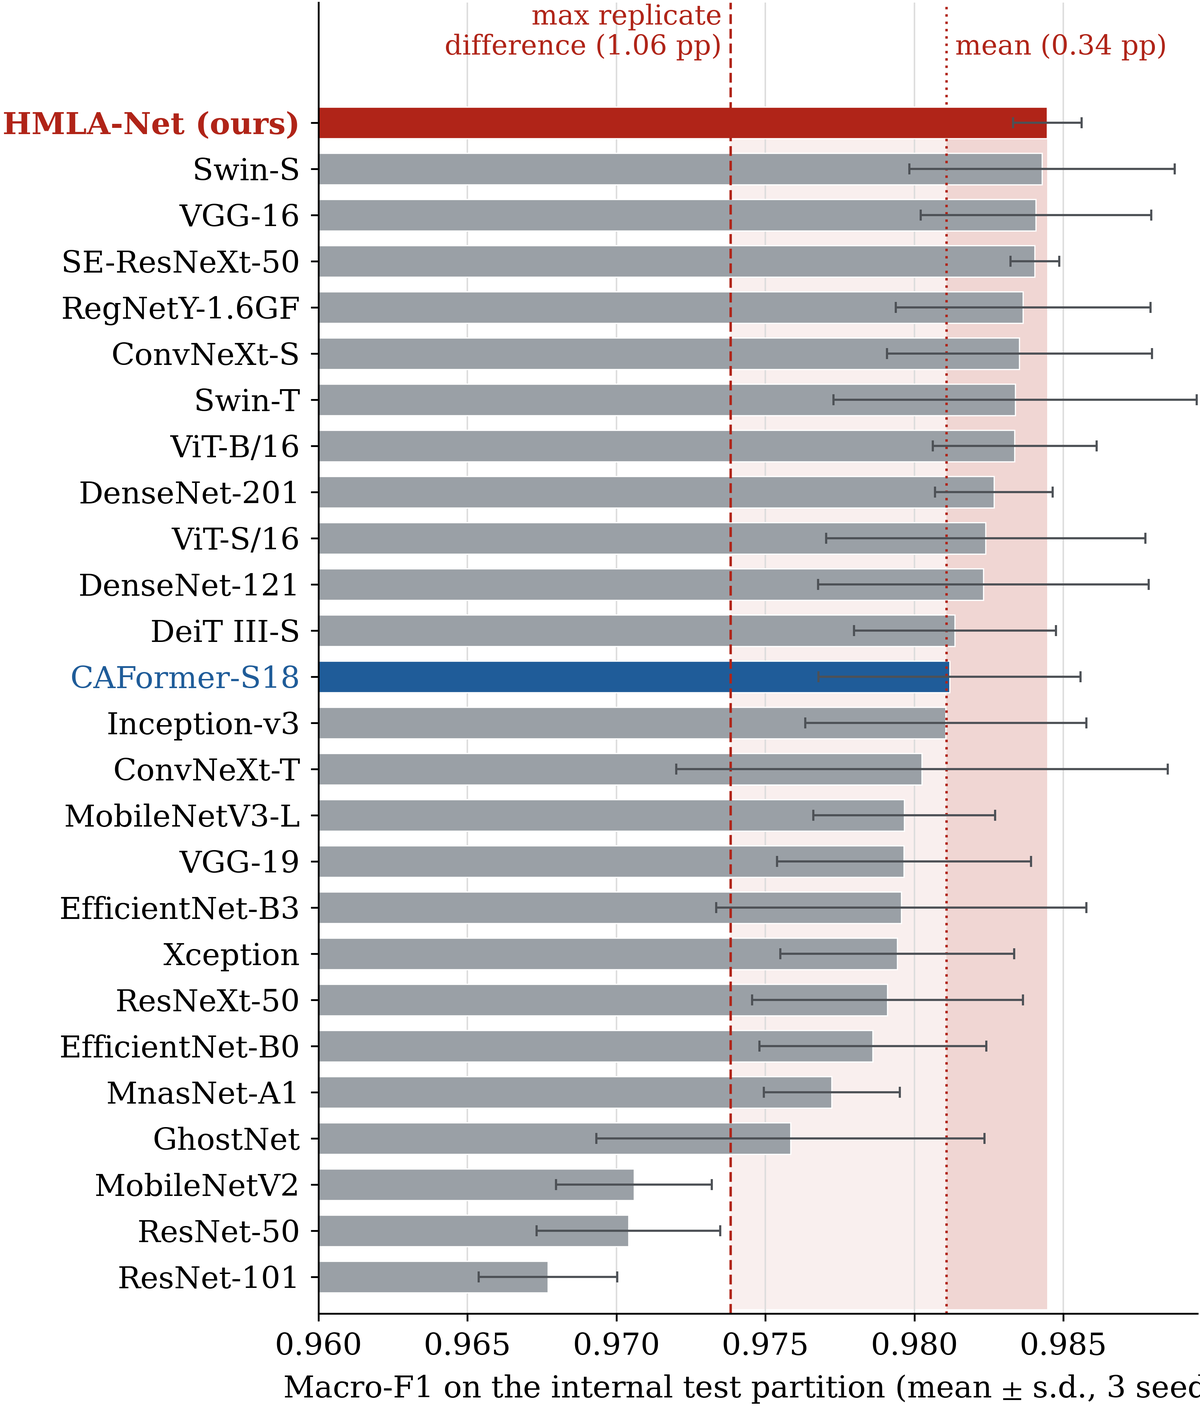

fig4_cd_diagram.png -> (1200, 1056)


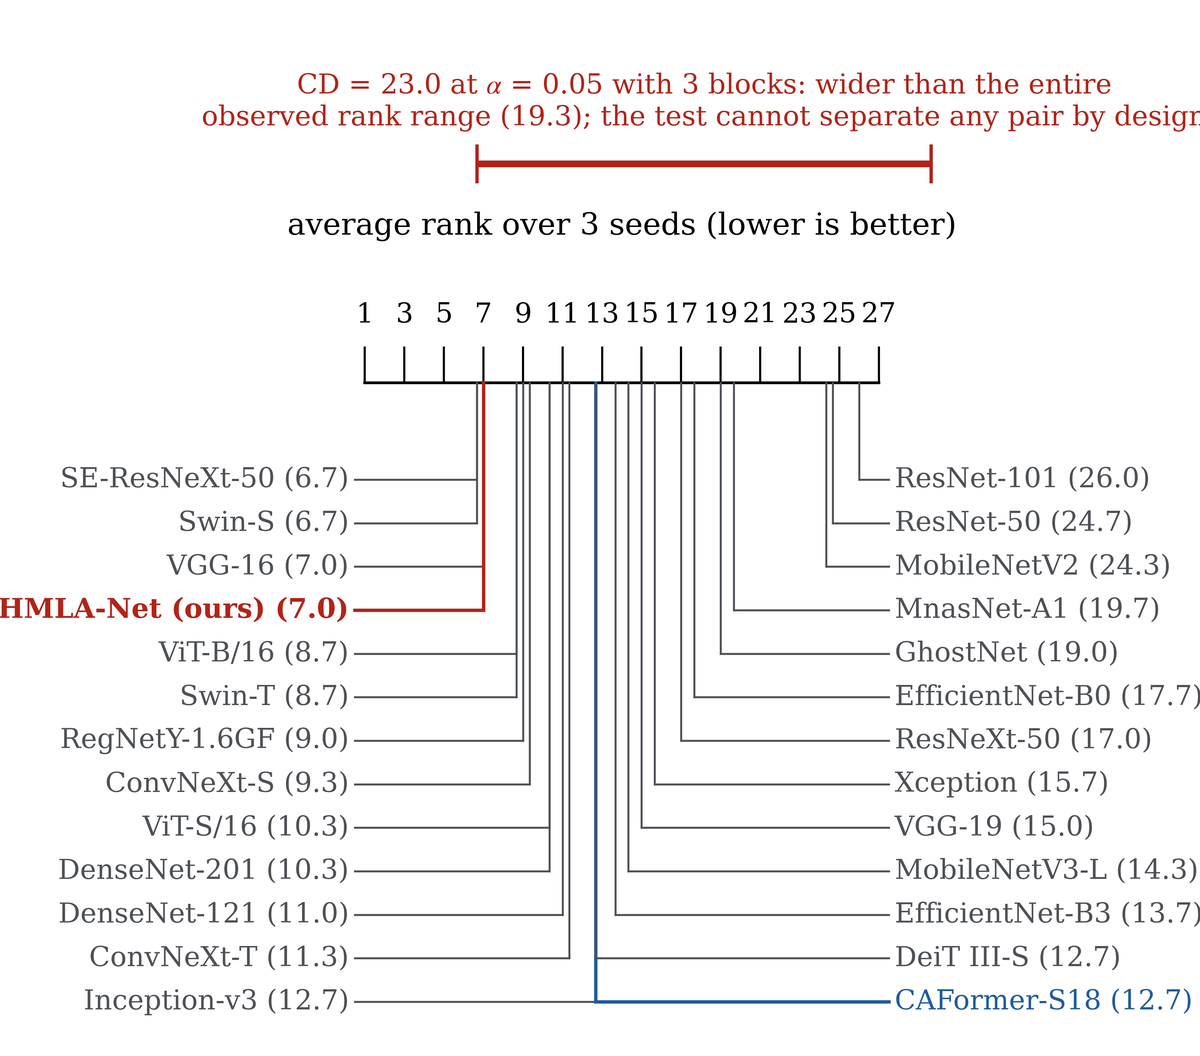

fig5_transfer.png -> (1200, 1276)


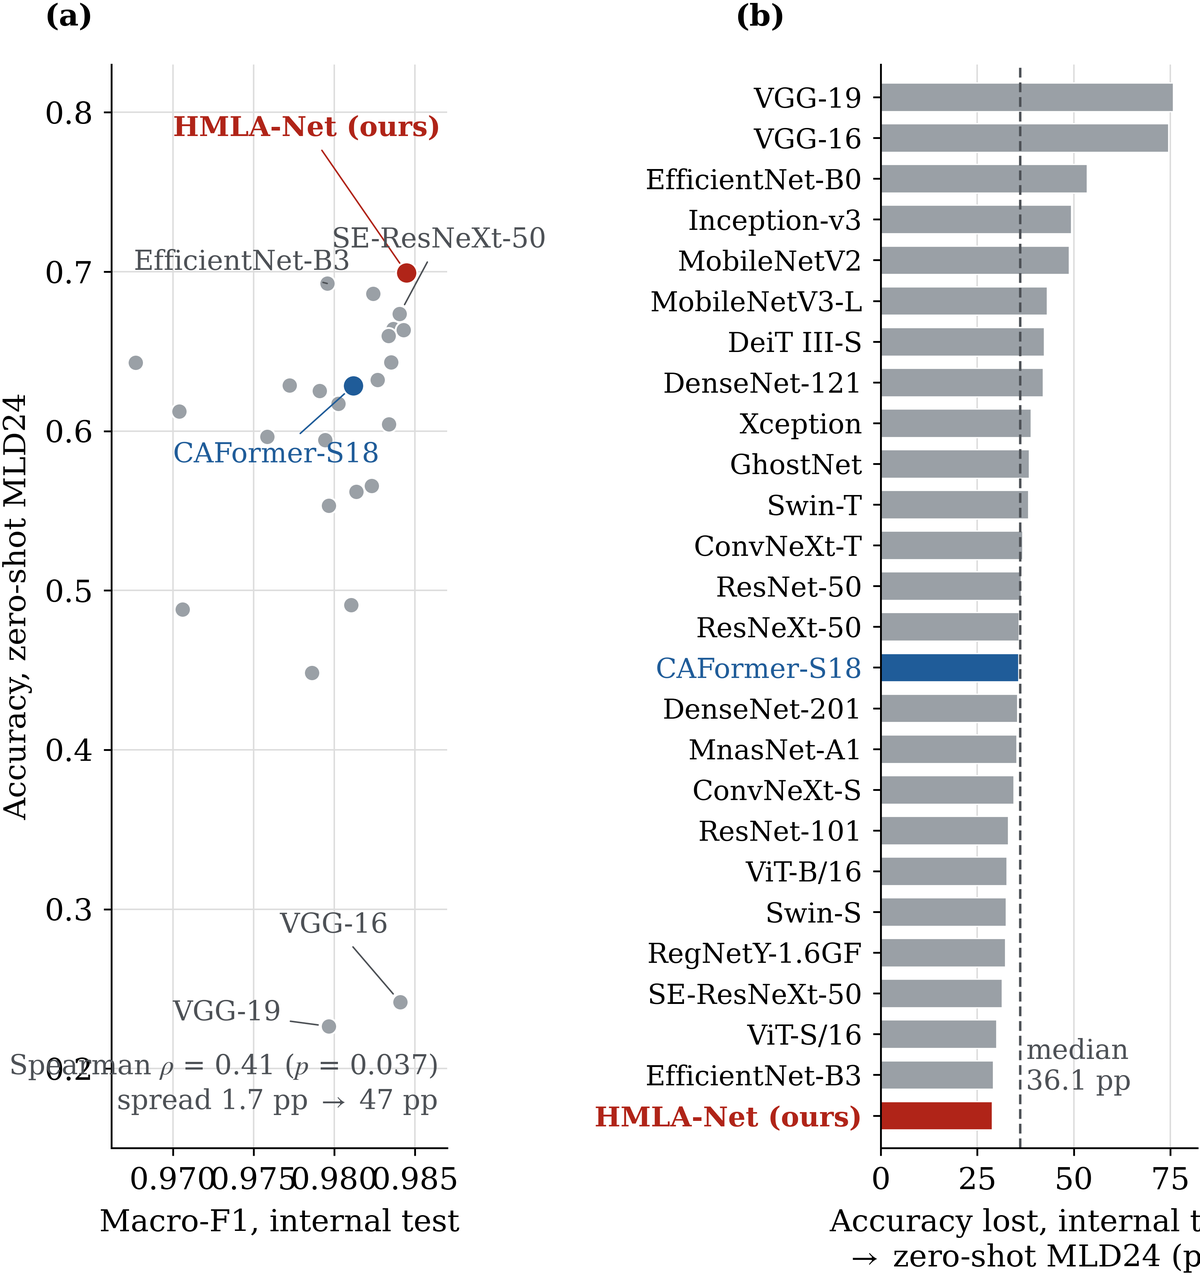

fig6_replication.png -> (1200, 1407)


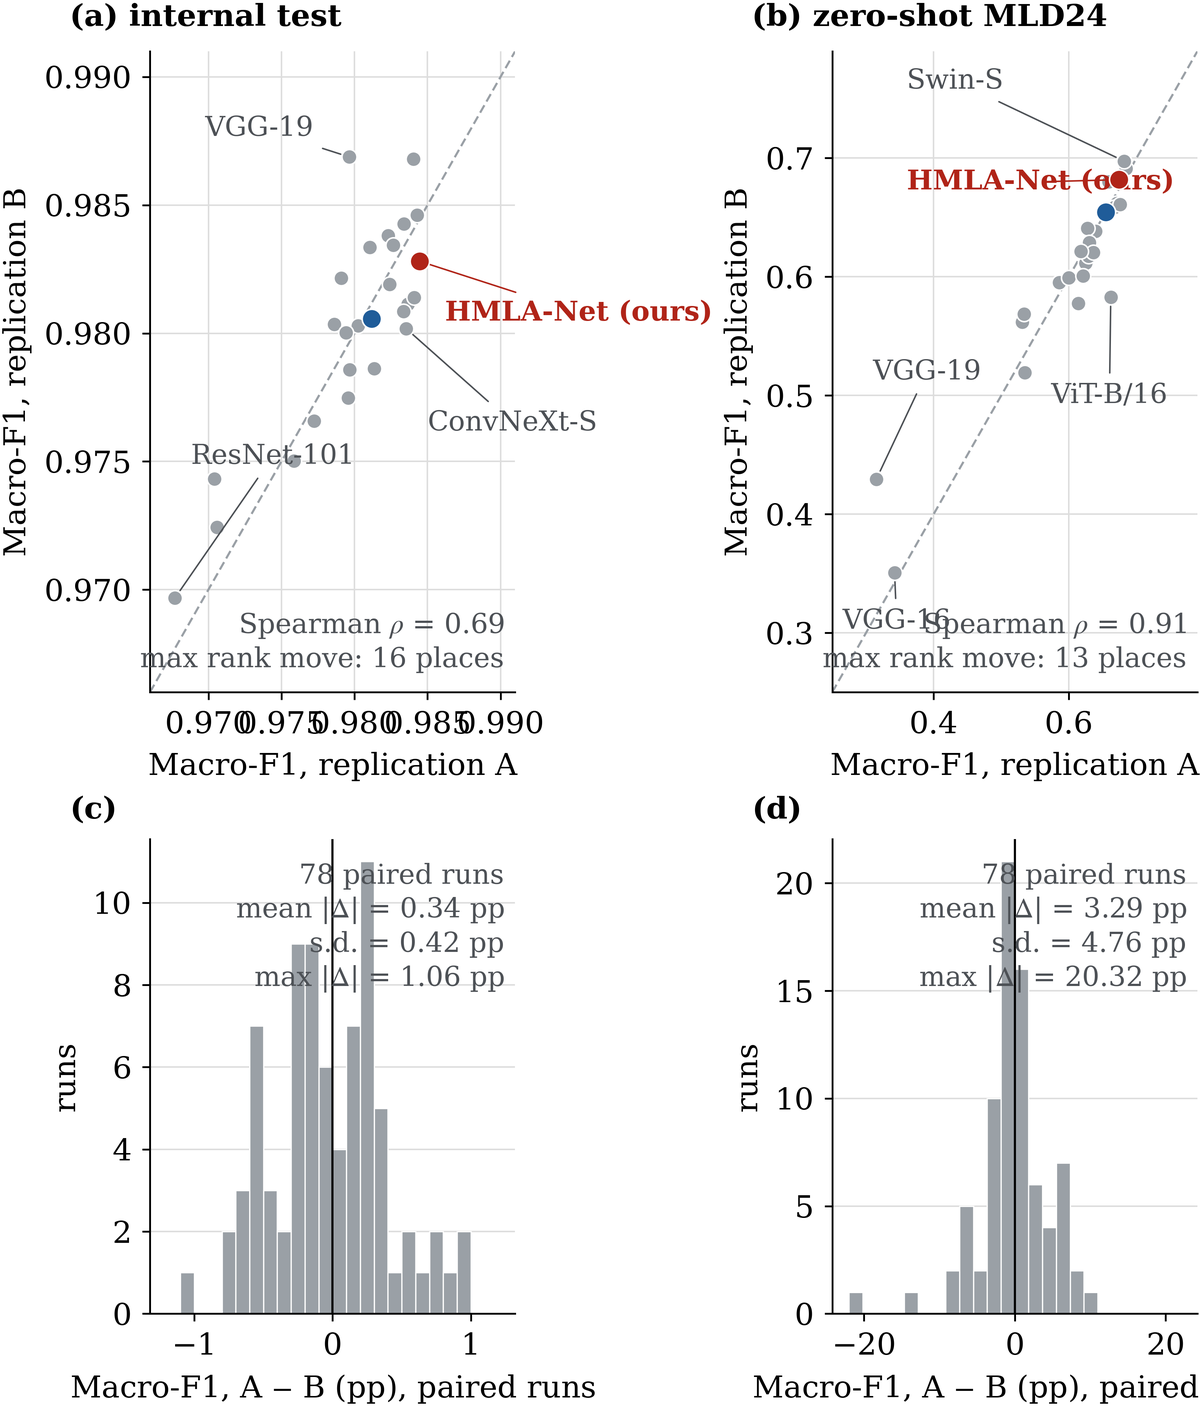

In [ ]:
from PIL import Image
from IPython.display import display

FIG_DIR = PAPER_DIR / "output/figures"
SHOW = ["fig3_internal_ranking.png", "fig4_cd_diagram.png",
        "fig5_transfer.png", "fig6_replication.png"]
available = sorted(p.name for p in FIG_DIR.glob("*.png"))
print("figures generated:", available)

for name in SHOW:
    p = FIG_DIR / name
    if not p.exists():
        print("missing:", name)
        continue
    im = Image.open(p)
    if im.width > 1200:
        im = im.resize((1200, round(im.height * 1200 / im.width)), Image.LANCZOS)
    print(name, "->", im.size)
    display(im)

## Recomputed statistics vs the archived copies / 統計の再計算と照合
Per `paper/README.md`, the summary tables and test statistics of replication A can be recomputed **in place** with the repository's `analyze.py`; the archived copies should reproduce the checked quantities (the README reports floating-point-identical agreement for the Friedman statistic, p, CD, per-seed McNemar p-values and Holm-corrected Wilcoxon). The cell runs the script and compares the regenerated `stats_report.json` against the archived Git `HEAD` copy with a recursive walk that (a) treats `NaN == NaN` as equal, like the authors' own `compare_numbers.py`, and (b) reports separately the fields where the archive stores `None` because the *optional* package `scikit-posthocs` was not installed in the authors' environment — on Colab it is present, so the Nemenyi p-matrix is computed. Any remaining numeric difference is a genuine mismatch and fails the cell. *(JA)* `analyze.py` で replication A の統計を再計算し、Git HEAD のアーカイブ版と再帰比較します。NaN 同士は等価、アーカイブが None（オプションの scikit-posthocs 未導入のため）で Colab で計算された項は別枠で表示し、それ以外の数値差は失敗とします。

In [ ]:
import math
import subprocess as sp

t0 = time.time()
proc = sp.run([sys.executable, "analyze.py", "--out_dir", "paper/replication_A/runs"],
              cwd=REPO, text=True)
print(f"\n[glue] analyze.py exit code: {proc.returncode}, wall time: {time.time()-t0:.1f} s")
if proc.returncode != 0:
    raise RuntimeError("analyze.py failed")

changed = sp.run(["git", "-C", str(REPO), "diff", "--name-only"],
                 capture_output=True, text=True, check=True).stdout.split()
print("files rewritten by analyze.py:", changed)

def walk_cmp(a, b, path="", out=None, tol=1e-9):
    out = [] if out is None else out
    if isinstance(a, dict) and isinstance(b, dict):
        for k in sorted(set(a) | set(b)):
            if k not in a or k not in b:
                out.append(("missing", f"{path}/{k}"))
            else:
                walk_cmp(a[k], b[k], f"{path}/{k}", out, tol)
    elif isinstance(a, list) and isinstance(b, list):
        if len(a) != len(b):
            out.append(("missing", f"{path}: length {len(a)} != {len(b)}"))
        else:
            for i, (x, y) in enumerate(zip(a, b)):
                walk_cmp(x, y, f"{path}[{i}]", out, tol)
    elif isinstance(a, (int, float)) and isinstance(b, (int, float)):
        both_nan = isinstance(a, float) and isinstance(b, float) and math.isnan(a) and math.isnan(b)
        if not (both_nan or a == b or abs(a - b) < tol):
            out.append(("mismatch", f"{path}: {a} vs {b}"))
    elif a != b:
        out.append(("type", f"{path}: {type(a).__name__} vs {type(b).__name__}: {str(a)[:40]} vs {str(b)[:40]}"))
    return out

old = json.loads(sp.run(["git", "-C", str(REPO), "show",
                         "HEAD:paper/replication_A/runs/stats_report.json"],
                        capture_output=True, text=True, check=True).stdout)
new = json.loads((REPO / "paper/replication_A/runs/stats_report.json").read_text())
diffs = walk_cmp(old, new)
kinds = {}
for kind, d in diffs:
    kinds.setdefault(kind, []).append(d)
print("archived-vs-regenerated: numeric mismatches:", len(kinds.get("mismatch", [])))
for d in kinds.get("mismatch", [])[:10]:
    print("  MISMATCH", d)
optional = [d for d in kinds.get("type", []) if "NoneType" in d]
print("archive-None fields computed on Colab (optional scikit-posthocs):", len(optional))
for d in optional:
    print("  OPTIONAL", d[:120])
missing = kinds.get("missing", [])
print("missing keys:", len(missing))
for d in missing[:10]:
    print("  MISSING", d[:120])
assert not kinds.get("mismatch") and not missing, "genuine archived-vs-regenerated differences found"



[glue] analyze.py exit code: 0, wall time: 4.2 s


files rewritten by analyze.py: ['paper/output/derived/_A_extra.json', 'paper/output/derived/_A_protocols.csv', 'paper/output/derived/_internal_A.csv', 'paper/output/derived/_per_class_external_A.csv', 'paper/output/derived/_per_class_external_B.csv', 'paper/output/numbers.json', 'paper/replication_A/runs/ablation_summary.csv', 'paper/replication_A/runs/cd_diagram.png', 'paper/replication_A/runs/complexity.csv', 'paper/replication_A/runs/efficiency_test.png', 'paper/replication_A/runs/mcnemar.json', 'paper/replication_A/runs/proposed_vs_baselines.csv', 'paper/replication_A/runs/ranking_test.png', 'paper/replication_A/runs/stats_report.json', 'paper/replication_A/runs/summary_external.csv', 'paper/replication_A/runs/summary_internal_test.csv']
archived-vs-regenerated: numeric mismatches: 0
archive-None fields computed on Colab (optional scikit-posthocs): 2
  OPTIONAL /friedman_nemenyi/nemenyi_pmatrix: dict vs NoneType: {'Proposed_HMLA_CAFormerS18': {'Proposed vs None
  OPTIONAL /friedman

## Interpretation and validation record / 解釈と検証記録

**How to read the result.** If the run above reached this cell, the authors' chain regenerated every quoted number from the archived run outputs and `compare_numbers.py` confirmed exact agreement with the frozen reference; the recomputed replication-A statistics showed no genuine numeric difference from the archived copies (NaN-equality handled as in `compare_numbers.py`; the only regenerated-only field is the Nemenyi p-matrix, which the archive stores as `null` because the optional `scikit-posthocs` was absent in the authors' environment — see the categorized output above). This validates the paper's *reporting chain* — that the manuscript's tables, figures and statistics follow from its archived artifacts — on a fresh, independent runtime. It does **not** re-train or re-evaluate the models and does not by itself verify dataset-level accuracy claims made in the article body (full text was not consulted for this scope).

**Validation record.** Executed on a fresh Google Colab CPU runtime via the Colab CLI (session and date recorded in the project report; measured wall times are printed by the run cells above). Free-tier availability and speeds may differ. *(JA)* 本セルに到達していれば、アーカイブ済み実行結果から著者チェーンがすべての引用数値を再生し、参照コピーと完全一致すること、および再計算統計がアーカイブと数値的に一致することが確認済みです。これは報告チェーンの検証であり、再学習・再評価ではありません。

**References.** Karakus & Burukanli, Symmetry 2026, 18(9), 1557, DOI 10.3390/sym18091557 · code `songulkarakus/HMLA-Net` @ `101f31a461a1a5782d25e616b235f71ced90b21c`, MIT License · paper archive `paper/README.md` and `paper/MANIFEST.md` · internal corpus Srabon et al., Mendeley Data doi:10.17632/3xd9n7jpc8.1 · external corpus MLD24, Mendeley Data doi:10.17632/6dvpywm2m2.1 (not used in this scope).